# Model development

We use the sample prepared in Notebook 01 to predict UCLA loneliness scores.

## 1 Import libraries and set paths

We use separate folders for the modelling tables and figures.

In [15]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
processed = root / "data/processed"
tables = root / "results/tables/modelling"
figures = root / "results/figures/presentation2"
for folder in (tables, figures):
    folder.mkdir(parents=True, exist_ok=True)

## 2 Load the sample and define predictor sets

Loneliness may also relate to people's relationships, household and wider circumstances. We compare the two contact measures alone and alongside the context variables to see how much each adds to prediction.

In [16]:
sample_path = processed / "eu_loneliness_analysis_sample.csv"
sample = pd.read_csv(sample_path)
target = "ucla_total"
face, remote = "friends_meet_face", "friends_meet_tele"
numeric = ["age", "close_friends_n", "adults_n", "childr_n_0to5",
           "childr_n_6to15", "others_n"]
categorical = ["gender", "relationship", "education", "work_status",
               "municipality_type", "country"]
context = numeric + categorical
full = context + [face, remote]
predictor_sets = {
    "Face-to-face only": [face], "Remote only": [remote],
    "Both contact types": [face, remote], "Context only": context,
    "Context + face-to-face": context + [face], "Context + remote": context + [remote],
    "Context + both": full,
}
sample[full].isna().mean().rename("missing_share").to_csv(tables / "predictor_missingness.csv")

## 3 Split the data

We hold back 20% of respondents to estimate how well the fitted models predict scores for people they haven't seen. We use the same five training folds for every model so their validation scores are directly comparable.

In [17]:
train, test = train_test_split(sample.index.to_numpy(), test_size=0.2, random_state=42)
folds = KFold(n_splits=5, shuffle=True, random_state=42)
display(pd.Series({"training": len(train), "test": len(test)}, name="respondents"))

training    19544
test         4887
Name: respondents, dtype: int64

## 4 Set up preprocessing and model fitting

We fill in missing context values so respondents can stay in the analysis. We encode categories and scale numerical predictors for the linear models. The pipeline learns these steps from the training rows in each fold so information from validation and test rows cannot influence the fit.

In [18]:
def compare(model, grid, features, scale=False):
    numbers = [name for name in features if name not in categorical]
    categories = [name for name in features if name in categorical]
    numeric_steps = [SimpleImputer(strategy="median", add_indicator=True)]
    if scale:
        numeric_steps.append(StandardScaler())
    encoding = make_pipeline(
        SimpleImputer(strategy="constant", fill_value=-1),
        OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
    )
    prep = ColumnTransformer([
        ("numeric", make_pipeline(*numeric_steps), numbers),
        ("categorical", encoding, categories),
    ])
    search = GridSearchCV(
        make_pipeline(prep, model), grid, cv=folds, n_jobs=2,
        scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error",
                 "r2": "r2"},
        refit="mae", return_train_score=True, error_score="raise",
    )
    search.fit(sample.loc[train, features], sample.loc[train, target])
    return search

## 5 Compare models

The mean and median baselines show how well we can predict using a single score for everyone. We choose the final model using cross-validation MAE because it expresses the average size of a prediction error in loneliness points.

,MAE,RMSE,R2,parameters
model,,,,
Random forest,1.398,1.694,0.162,"{'randomforestregressor__max_depth': None, 'ra..."
Ridge,1.418,1.717,0.138,{'ridge__alpha': 1}
Linear regression,1.418,1.717,0.138,{}
Decision tree,1.429,1.727,0.128,{'decisiontreeregressor__max_depth': 6}
Median baseline,1.558,1.850,-0.000,{}
Mean baseline,1.559,1.850,-0.000,{}


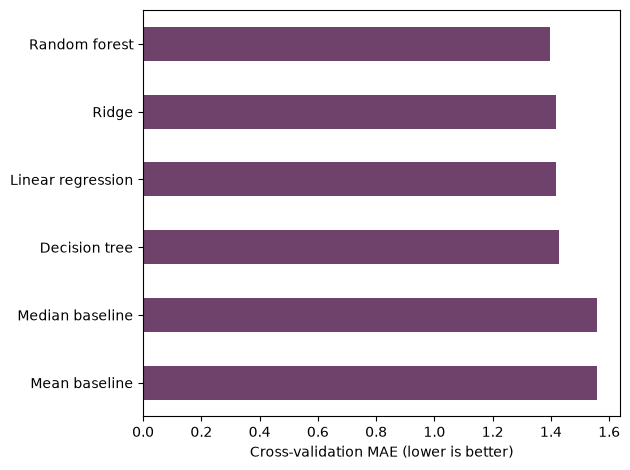

In [19]:
alpha_grid = {"ridge__alpha": [0.1, 1, 10, 100, 1000]}
candidates = {
    "Median baseline": (DummyRegressor(strategy="median"), {}, False),
    "Mean baseline": (DummyRegressor(strategy="mean"), {}, False),
    "Linear regression": (LinearRegression(), {}, True),
    "Ridge": (Ridge(), alpha_grid, True),
    "Decision tree": (DecisionTreeRegressor(min_samples_leaf=20, random_state=42),
                      {"decisiontreeregressor__max_depth": [2, 4, 6, 10, None]}, False),
    "Random forest": (RandomForestRegressor(n_estimators=150, max_features=0.7, random_state=42),
                      {"randomforestregressor__max_depth": [8, None],
                       "randomforestregressor__min_samples_leaf": [20, 80]}, False),
}
searches = {name: compare(model, grid, full, scale)
            for name, (model, grid, scale) in candidates.items()}

def cv_summary(fitted):
    rows = []
    for name, search in fitted.items():
        results = search.cv_results_
        i = search.best_index_
        rows.append({"model": name, "MAE": -results["mean_test_mae"][i],
                     "RMSE": -results["mean_test_rmse"][i], "R2": results["mean_test_r2"][i],
                     "parameters": str(search.best_params_)})
    return pd.DataFrame(rows).set_index("model").sort_values("MAE")

scores = cv_summary(searches)
selected = scores.index[0]
scores.to_csv(tables / "model_selection_cv.csv")
display(scores.round(3))
ax = scores["MAE"].sort_values(ascending=False).plot.barh(color="#6e426a")
ax.set(xlabel="Cross-validation MAE (lower is better)", ylabel="")
plt.tight_layout()
plt.savefig(figures / "01_model_comparison_cv.png", dpi=180)
plt.show()

## 6 Check tree depth

Deeper trees can fit the training data more closely, but that can also mean fitting patterns that don't carry over to new respondents. We plot training and validation MAE together to see where validation error starts to rise.

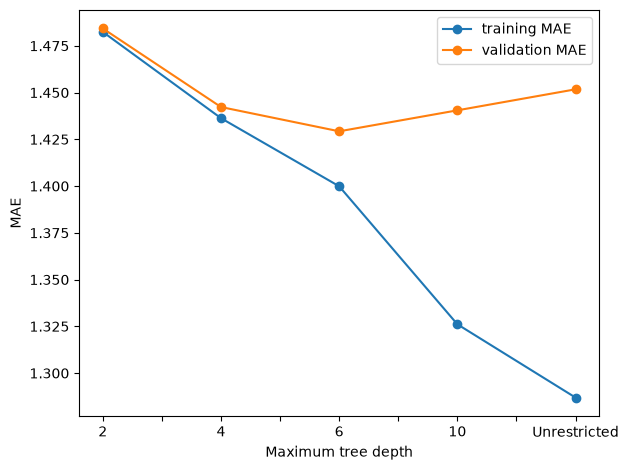

In [20]:
tree = pd.DataFrame(searches["Decision tree"].cv_results_)
tree["depth"] = tree["param_decisiontreeregressor__max_depth"].fillna("Unrestricted").astype(str)
tree["training MAE"] = -tree["mean_train_mae"]
tree["validation MAE"] = -tree["mean_test_mae"]
ax = tree.set_index("depth")[["training MAE", "validation MAE"]].plot(marker="o")
ax.set(xlabel="Maximum tree depth", ylabel="MAE")
plt.tight_layout()
plt.savefig(figures / "02_tree_complexity.png", dpi=180)
plt.show()

## 7 Compare predictor sets

We use Ridge for each predictor set so the model type stays consistent. Comparing context alone with context plus contact shows whether knowing how often people see or speak to friends improves predictions.

In [21]:
ridge_searches = {
    name: searches["Ridge"] if name == "Context + both" else compare(Ridge(), alpha_grid, features, True)
    for name, features in predictor_sets.items()
}
predictor_scores = cv_summary(ridge_searches)
predictor_scores.to_csv(tables / "predictor_sets_cv.csv")
display(predictor_scores.round(3))

,MAE,RMSE,R2,parameters
model,,,,
Context + both,1.418,1.717,0.138,{'ridge__alpha': 1}
Context + face-to-face,1.423,1.722,0.134,{'ridge__alpha': 1}
Context + remote,1.429,1.727,0.128,{'ridge__alpha': 1}
Context only,1.456,1.752,0.104,{'ridge__alpha': 1}
Both contact types,1.544,1.817,0.036,{'ridge__alpha': 0.1}
Face-to-face only,1.548,1.820,0.032,{'ridge__alpha': 0.1}
Remote only,1.552,1.827,0.025,{'ridge__alpha': 0.1}


## 8 Export the results and fitted models

We save the fitted models locally for Notebook 04.

In [22]:
for name, search in searches.items():
    filename = name.lower().replace(" ", "_") + "_grid.csv"
    pd.DataFrame(search.cv_results_).to_csv(tables / filename, index=False)

joblib.dump({
    "test": test, "selected": selected,
    "models": {name: searches[name].best_estimator_ for name in
               dict.fromkeys([selected, "Median baseline", "Mean baseline"])},
    "ridge_models": {name: search.best_estimator_ for name, search in ridge_searches.items()},
    "full": full, "predictor_sets": predictor_sets,
}, processed / "presentation2_models.joblib")

['/Users/ellabodkin/Documents/GitHub/ProjectCSC1169/data/processed/presentation2_models.joblib']

## 9 Summary

The random forest had the lowest cross-validation MAE. We evaluate it and the Ridge predictor comparisons on the held-out sample in Notebook 04.